In [1]:
from pathlib import Path

import pandas as pd

# In a notebook, __file__ does not exist, so we start from the current folder
project = Path.cwd().parent
clean_file = project / "data" / "processed" / "superstore_clean.csv"

df = pd.read_csv(
    clean_file,
    dtype={"Postal Code": str},
    parse_dates=["Order Date", "Ship Date", "Order Month"],
)
print("Project folder:", project)
print("Rows:", len(df), "| Columns:", df.shape[1])
print("Total Sales:", round(df["Sales"].sum(), 2))

Project folder: C:\Users\user\PycharmProjects\sales-forecasting-project
Rows: 9994 | Columns: 24
Total Sales: 2297200.86


# Sales Performance and Forecasting Report

**Data:** Sample - Superstore (orders from Jan 2014 to Dec 2017). The currency is not stated in the file; it is assumed to be USD.

**Purpose:** Analyze historical sales and profit, then forecast monthly sales for six months. The data ends in Dec 2017, so the forecast is a practice exercise on historical data.

## 1. Headline KPIs

Definitions: Profit Margin = total profit / total sales. Number of Orders counts distinct Order IDs, not rows.

In [2]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_sales
orders = df["Order ID"].nunique()
units = df["Quantity"].sum()
avg_order_value = total_sales / orders
avg_discount = df["Discount"].mean()
loss_lines = (df["Profit"] < 0).sum()

# Consistency check: these must match the figures from our earlier Python scripts
assert round(total_sales, 2) == 2297200.86
assert round(total_profit, 2) == 286397.02
assert orders == 5009

kpis = pd.DataFrame({
    "KPI": ["Total Sales", "Total Profit", "Profit Margin", "Number of Orders",
            "Units Sold", "Average Order Value", "Average Discount", "Loss-Making Lines"],
    "Value": [f"${total_sales:,.2f}", f"${total_profit:,.2f}", f"{profit_margin:.2%}",
              f"{orders:,}", f"{units:,}", f"${avg_order_value:,.2f}",
              f"{avg_discount:.2%}", f"{loss_lines:,} of {len(df):,} ({loss_lines / len(df):.1%})"],
})
kpis

,KPI,Value
0,Total Sales,"$2,297,200.86"
1,Total Profit,"$286,397.02"
2,Profit Margin,12.47%
3,Number of Orders,"5,009"
4,Units Sold,"37,873"
5,Average Order Value,$458.61
6,Average Discount,15.62%
7,Loss-Making Lines,"1,871 of 9,994 (18.7%)"


## 2. Sales and profit trends

First a year-by-year summary, then the monthly pattern.

In [3]:
yearly = df.groupby("Order Year").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Units=("Quantity", "sum"),
)
yearly["Profit Margin"] = yearly["Profit"] / yearly["Sales"]
yearly["Sales Growth"] = yearly["Sales"].pct_change()
yearly["Avg Order Value"] = yearly["Sales"] / yearly["Orders"]

# The yearly rows must add back to the overall total
assert round(yearly["Sales"].sum(), 2) == round(total_sales, 2)

yearly.round({"Sales": 0, "Profit": 0, "Profit Margin": 3,
              "Sales Growth": 3, "Avg Order Value": 2})

,Sales,Profit,Orders,Units,Profit Margin,Sales Growth,Avg Order Value
Order Year,,,,,,,
2014,484247.0,49544.0,969,7581,0.102,NaN,499.74
2015,470533.0,61619.0,1038,7979,0.131,-0.028,453.31
2016,609206.0,81795.0,1315,9837,0.134,0.295,463.27
2017,733215.0,93439.0,1687,12476,0.127,0.204,434.63


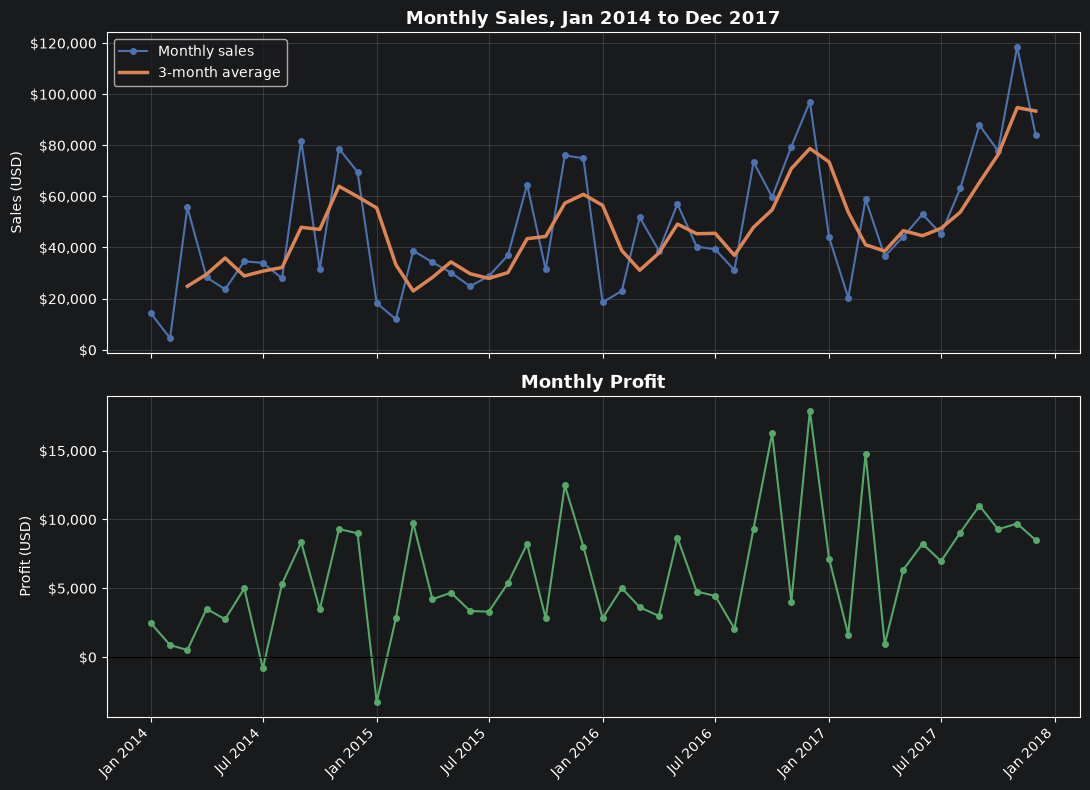

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

monthly = df.groupby("Order Month").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
).reset_index()
monthly["Profit Margin"] = monthly["Profit"] / monthly["Sales"]
monthly["Sales 3M Avg"] = monthly["Sales"].rolling(window=3).mean()

assert len(monthly) == 48
assert round(monthly["Sales"].sum(), 2) == round(total_sales, 2)

dollars = FuncFormatter(lambda x, pos: f"${x:,.0f}")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

ax1.plot(monthly["Order Month"], monthly["Sales"], marker="o", markersize=4,
         color="#4C72B0", label="Monthly sales")
ax1.plot(monthly["Order Month"], monthly["Sales 3M Avg"], linewidth=2.5,
         color="#DD8452", label="3-month average")
ax1.set_title("Monthly Sales, Jan 2014 to Dec 2017", fontsize=13, fontweight="bold")
ax1.set_ylabel("Sales (USD)")
ax1.yaxis.set_major_formatter(dollars)
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(monthly["Order Month"], monthly["Profit"], marker="o", markersize=4, color="#55A868")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Monthly Profit", fontsize=13, fontweight="bold")
ax2.set_ylabel("Profit (USD)")
ax2.yaxis.set_major_formatter(dollars)
ax2.grid(alpha=0.3)

ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()
plt.show()

### Findings: trends

**What the data shows**
- Annual sales were \$484K (2014), \$471K (2015), \$609K (2016) and \$733K (2017). 2015 dipped by 2.8%, and 2016 and 2017 grew by 29.5% and 20.4%.
- The number of orders rose every year, from 969 to 1,687, while the average order value fell from \$499.74 to \$434.63.
- Only 2 of 48 months lost money: July 2014 and January 2015.

**Interpretation** (my own reading)
- Orders grew faster than sales. This may mean customers placed more orders but each one was smaller, or more of the sales came from smaller items. This analysis doesn't prove which one it is.
- This matters to management because growth in sales is not the same as growth in the number of customers or orders. If orders keep growing while order value keeps falling, handling costs per dollar of sales could rise, so budgets should watch both numbers.

**Not yet explained**
- Why 2015 sales dipped even though orders increased. I haven't checked which products or customers changed that year.

## 3. Seasonality

Sales grew over the four years, so comparing raw dollars by month would favor later years. Instead, this section shows each month's **share of that year's total sales**. If sales were spread perfectly evenly, every month would be about 8.3% (1/12).

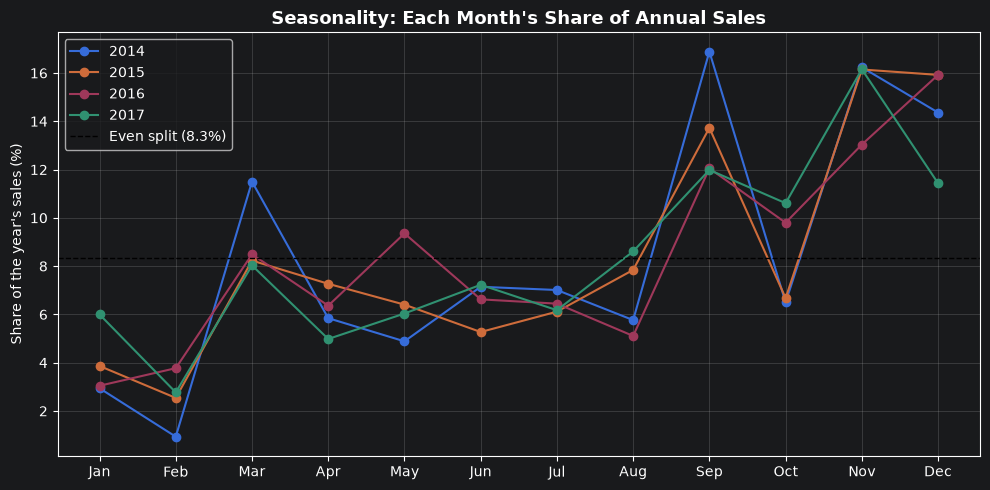

Year,2014,2015,2016,2017
Month,,,,
1,0.029,0.039,0.030,0.060
2,0.009,0.025,0.038,0.028
3,0.115,0.082,0.085,0.080
4,0.058,0.073,0.064,0.050
5,0.049,0.064,0.094,0.060
6,0.071,0.053,0.066,0.072
7,0.070,0.061,0.064,0.062
8,0.058,0.078,0.051,0.086
9,0.169,0.137,0.121,0.120


In [5]:
import numpy as np

monthly["Year"] = monthly["Order Month"].dt.year
monthly["Month"] = monthly["Order Month"].dt.month

pivot = monthly.pivot(index="Month", columns="Year", values="Sales")
share = pivot / pivot.sum()          # each year's 12 shares add up to 1
assert np.allclose(share.sum(), 1)

fig, ax = plt.subplots(figsize=(10, 5))
for year in share.columns:
    ax.plot(share.index, share[year] * 100, marker="o", label=str(year))
ax.axhline(100 / 12, color="black", linestyle="--", linewidth=1, label="Even split (8.3%)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Share of the year's sales (%)")
ax.set_title("Seasonality: Each Month's Share of Annual Sales", fontsize=13, fontweight="bold")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

share.round(3)

### Findings: seasonality

**What the data shows**
- September, November and December each had an above-average share of sales in all four years. Together they made up about 43% of annual sales, compared with 25% if sales were spread evenly.
- January and February were below average every year, together about 6.5% of annual sales.
- A small number of very large orders can swing a month. For example, one Cisco order was about 41% of March 2014 sales.

**Interpretation** (my own reading)
- There seems to be a repeating yearly pattern: slow start, strong end. The fact that it appears in all four years makes me trust it more than a one-year pattern.
- Four years is a small sample, and big one-off orders may exaggerate some peaks, so I treat this as a pattern to plan around, not a rule.

**Not yet explained**
- I haven't checked whether the pattern stays the same after removing the biggest orders, so I can't say how much of it comes from a few large purchases.

## 4. Category, region and sub-category performance

Profit margin is always total profit divided by total sales for the group, never an average of row margins.

BY CATEGORY
                    Sales    Profit  Avg_Discount  Profit Margin
Category                                                        
Technology       836154.0  145455.0         0.132          0.174
Office Supplies  719047.0  122491.0         0.157          0.170
Furniture        742000.0   18451.0         0.174          0.025

BY REGION
            Sales    Profit  Avg_Discount  Profit Margin
Region                                                  
West     725458.0  108418.0         0.109          0.149
East     678781.0   91523.0         0.145          0.135
South    391722.0   46749.0         0.147          0.119
Central  501240.0   39706.0         0.240          0.079


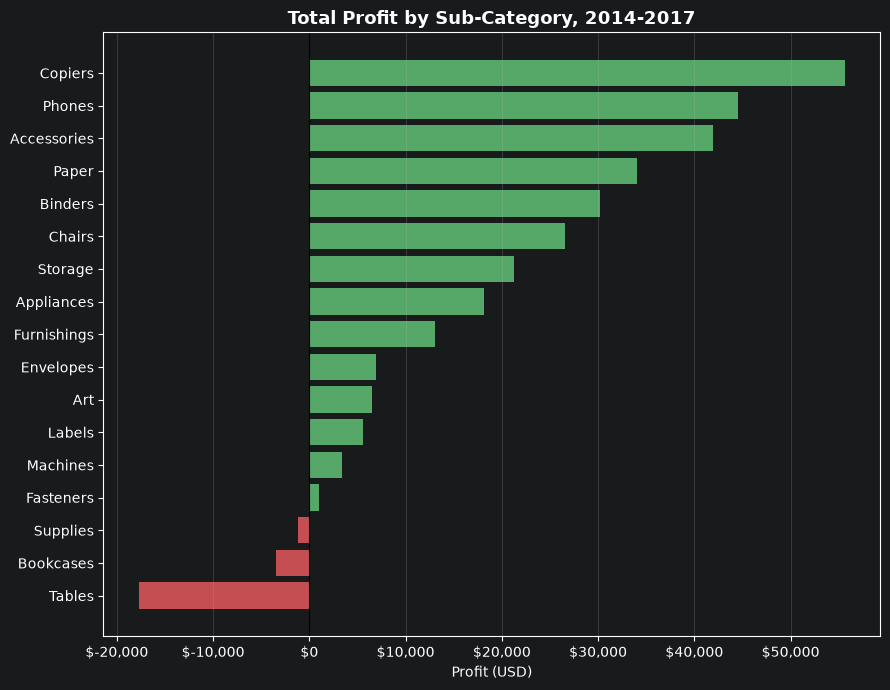

In [6]:
def summarize(group_col):
    out = df.groupby(group_col).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Avg_Discount=("Discount", "mean"),
    )
    out["Profit Margin"] = out["Profit"] / out["Sales"]
    # Each summary must add back to the overall totals
    assert np.isclose(out["Sales"].sum(), df["Sales"].sum())
    assert np.isclose(out["Profit"].sum(), df["Profit"].sum())
    return out.sort_values("Profit", ascending=False)

rounding = {"Sales": 0, "Profit": 0, "Avg_Discount": 3, "Profit Margin": 3}
category = summarize("Category").round(rounding)
region = summarize("Region").round(rounding)
sub = summarize("Sub-Category")

print("BY CATEGORY")
print(category)
print("\nBY REGION")
print(region)

# Chart: profit by sub-category (red = loss, green = profit)
sub_profit = sub["Profit"].sort_values()
colors = ["#C44E52" if v < 0 else "#55A868" for v in sub_profit]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(sub_profit.index, sub_profit.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Total Profit by Sub-Category, 2014-2017", fontsize=13, fontweight="bold")
ax.set_xlabel("Profit (USD)")
ax.xaxis.set_major_formatter(dollars)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

### Findings: category, region and sub-category

**What the data shows**
- Technology had the highest sales (\$836K) and profit (\$145K). Furniture had sales of \$742K but only \$18K of profit, a 2.5% margin, compared with about 17% for Technology and Office Supplies.
- Three sub-categories lost money overall: Tables (-\$17.7K), Bookcases (-\$3.5K) and Supplies (-\$1.2K).
- West had the highest margin (14.9%). Central had the lowest (7.9%) and also the highest average discount (24.0%).

**Interpretation** (my own reading)
- Furniture brings in a lot of sales but very little profit, so it is not helping profit growth much. Tables and Bookcases look like the main reason.
- Central's low margin goes together with heavy discounting. This is an association, not proof that discounts caused it, because Central may also sell a different mix of products.

**Not yet explained**
- Why Supplies lost money at a low average discount (7.7%), so discounts can't be the whole story.

## 5. Discounts and profitability

Each order line is placed in a discount band. Profit margin for each band is its total profit divided by its total sales.

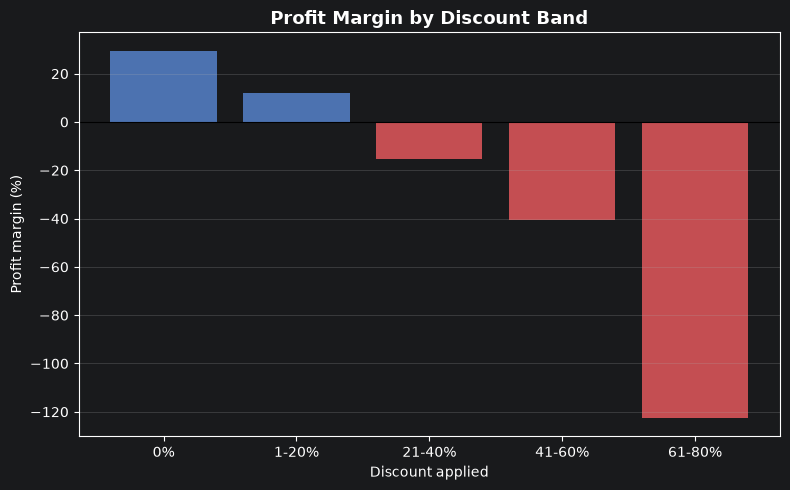

,Lines,Sales,Profit,Profit Margin
Discount,,,,
0%,4798,1087908.0,320988.0,0.295
1-20%,3803,846522.0,100785.0,0.119
21-40%,460,234138.0,-35817.0,-0.153
41-60%,215,71048.0,-28944.0,-0.407
61-80%,718,57584.0,-70614.0,-1.226


In [7]:
bands = pd.cut(
    df["Discount"],
    bins=[-0.001, 0.0, 0.2, 0.4, 0.6, 0.8],
    labels=["0%", "1-20%", "21-40%", "41-60%", "61-80%"],
)
assert bands.isna().sum() == 0          # every row must land in a band

by_band = df.groupby(bands, observed=True).agg(
    Lines=("Row ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
by_band["Profit Margin"] = by_band["Profit"] / by_band["Sales"]
assert by_band["Lines"].sum() == len(df)
assert np.isclose(by_band["Profit"].sum(), df["Profit"].sum())

fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = ["#C44E52" if v < 0 else "#4C72B0" for v in by_band["Profit Margin"]]
ax.bar(by_band.index.astype(str), by_band["Profit Margin"] * 100, color=bar_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit Margin by Discount Band", fontsize=13, fontweight="bold")
ax.set_xlabel("Discount applied")
ax.set_ylabel("Profit margin (%)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

by_band.round({"Sales": 0, "Profit": 0, "Profit Margin": 3})

### Findings: discounts

**What the data shows**
- Lines with no discount earned a 29.5% margin and about \$321K of profit. Lines with a 1-20% discount earned an 11.9% margin.
- Every band above 20% lost money. Those 1,393 lines (about 14% of all lines and 16% of sales) lost about \$135K combined, equal to about 47% of the \$286K total profit.
- In the 61-80% band, losses (\$70.6K) were larger than sales (\$57.6K).

**Interpretation** (my own reading)
- Heavy discounts go together with big losses, so discounts above 20% should be reviewed first.
- This is an association, not proof. Discounts may have been given to products that were already low margin, or to clear stock. The data can't separate those explanations.

**Not yet explained**
- Which products received the 61-80% discounts, and why. I also don't know whether 20% is a meaningful cutoff or just where this dataset happens to cross zero.

## 6. Top and bottom products

Products are ranked by total profit over the four years and grouped by Product Name (see the cleaning log for why Product ID is not used).

In [8]:
by_product = df.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
).sort_values("Profit", ascending=False)

# The product table must add back to the overall totals
assert np.isclose(by_product["Sales"].sum(), df["Sales"].sum())
assert np.isclose(by_product["Profit"].sum(), df["Profit"].sum())

print("Distinct products (by name):", len(by_product))
print("Loss-making products:", (by_product["Profit"] < 0).sum())

top10 = by_product.head(10).round(0)
bottom10 = by_product.tail(10).round(0)

print("\nTOP 10 BY PROFIT")
display(top10)
print("BOTTOM 10 BY PROFIT")
display(bottom10)

Distinct products (by name): 1850
Loss-making products: 301

TOP 10 BY PROFIT


,Sales,Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61600.0,25200.0
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.0,7753.0
Hewlett Packard LaserJet 3310 Copier,18840.0,6984.0
Canon PC1060 Personal Laser Copier,11620.0,4571.0
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18375.0,4095.0
Ativa V4110MDD Micro-Cut Shredder,7700.0,3773.0
"3D Systems Cube Printer, 2nd Generation, Magenta",14300.0,3718.0
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.0,3696.0
Ibico EPK-21 Electric Binding System,15876.0,3345.0


BOTTOM 10 BY PROFIT


,Sales,Profit
Product Name,,
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,1706.0,-1148.0
Balt Solid Wood Round Tables,6519.0,-1201.0
Martin Yale Chadless Opener Electric Letter Opener,16656.0,-1299.0
Cisco TelePresence System EX90 Videoconferencing Unit,22638.0,-1811.0
GBC DocuBind P400 Electric Binding System,17965.0,-1878.0
Bush Advantage Collection Racetrack Conference Table,9545.0,-1934.0
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9918.0,-2876.0
Cubify CubeX 3D Printer Triple Head Print,8000.0,-3840.0
Lexmark MX611dhe Monochrome Laser Printer,16830.0,-4590.0


### Findings: products

**What the data shows**
- The most profitable product, the Canon imageCLASS 2200 Advanced Copier, earned about \$25.2K, roughly 9% of all profit. The top 10 is mostly copiers, printers, binding machines and similar equipment.
- The biggest loss came from the Cubify CubeX 3D Printer (Double Head Print) at about -\$8.9K. A Lexmark laser printer and a second Cubify model are also in the bottom 10.
- Binding systems appear in both lists: the Ibico EPK-21 is in the top 10 (about \$3.3K profit), and the GBC DocuBind P400 is in the bottom 10 (about -\$1.9K).

**Interpretation** (my own reading)
- Profit depends heavily on a small number of products, so losing or mispricing one of them has a large effect.
- The same type of product can make money or lose money, so a category average doesn't tell you which items to fix. Product-level review is needed.

**Not yet explained**
- Why the bottom products lost money. The largest losing lines I checked earlier had discounts of 50 to 70%, but I haven't tested whether discounts explain every product in the bottom 10.

## 7. Forecasting

**Target:** monthly sales. **Split (chronological, never shuffled):** training data is Jan 2014 to Jun 2017 (42 months), and test data is Jul to Dec 2017 (6 months). Every forecast below is built from training data only.

**Baselines** (simple rules a real model must beat):
- Naive: every month equals the last training month.
- 3-month average: every month equals the average of the last 3 training months.
- Seasonal naive: each month equals the same month one year earlier.

Train: 2014-01-01 to 2017-06-01
Test:  2017-07-01 to 2017-12-01


,Actual,Naive,3-Month Avg,Seasonal Naive
Order Month,,,,
2017-07-01,45264.0,52982.0,44588.0,39262.0
2017-08-01,63121.0,52982.0,44588.0,31115.0
2017-09-01,87867.0,52982.0,44588.0,73410.0
2017-10-01,77777.0,52982.0,44588.0,59688.0
2017-11-01,118448.0,52982.0,44588.0,79412.0
2017-12-01,83829.0,52982.0,44588.0,96999.0


,MAE,RMSE,MAPE %
Naive,28975.0,34716.7,32.8
3-Month Avg,34796.2,41460.0,38.7
Seasonal Naive,20459.9,23430.2,25.4


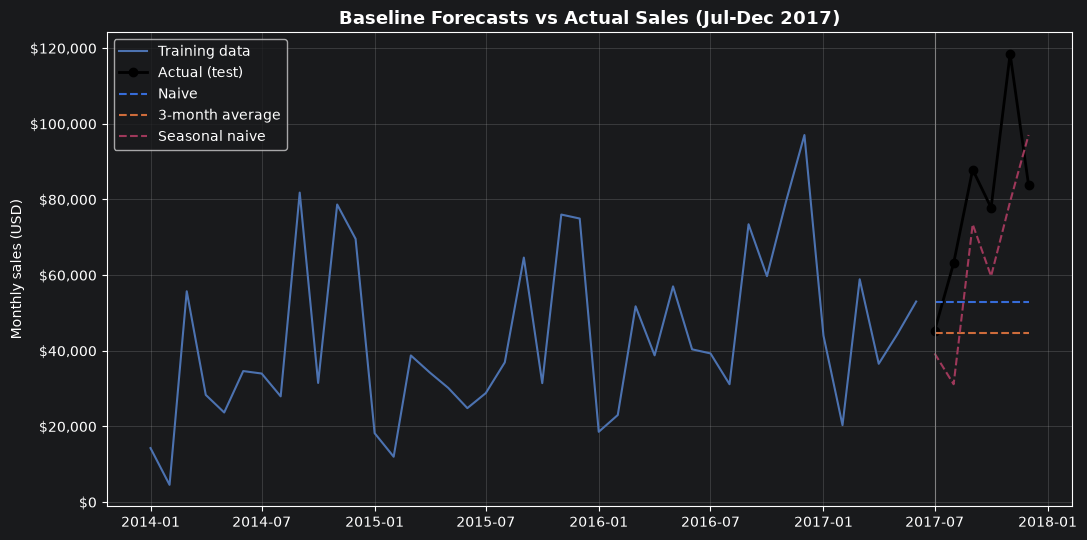

In [9]:
sales = monthly.set_index("Order Month")["Sales"].asfreq("MS")   # one value per month
H = 6                                                            # forecast horizon

train = sales.iloc[:-H]
test = sales.iloc[-H:]
assert len(train) == 42 and len(test) == 6
assert train.index.max() < test.index.min()   # training must come before testing

naive = pd.Series(train.iloc[-1], index=test.index)
avg3 = pd.Series(train.iloc[-3:].mean(), index=test.index)
seasonal_naive = pd.Series(
    [train.loc[d - pd.DateOffset(years=1)] for d in test.index], index=test.index
)

baselines = pd.DataFrame({
    "Actual": test, "Naive": naive, "3-Month Avg": avg3, "Seasonal Naive": seasonal_naive,
})


def accuracy(actual, predicted):
    error = actual - predicted
    return {
        "MAE": error.abs().mean(),                       # average miss in dollars
        "RMSE": np.sqrt((error ** 2).mean()),            # punishes big misses more
        "MAPE %": (error.abs() / actual).mean() * 100,   # average miss as % of actual
    }


baseline_scores = pd.DataFrame({
    name: accuracy(test, baselines[name]) for name in ["Naive", "3-Month Avg", "Seasonal Naive"]
}).T

print("Train:", train.index.min().date(), "to", train.index.max().date())
print("Test: ", test.index.min().date(), "to", test.index.max().date())
display(baselines.round(0))
display(baseline_scores.round(1))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(train.index, train, color="#4C72B0", label="Training data")
ax.plot(test.index, test, color="black", marker="o", linewidth=2, label="Actual (test)")
ax.plot(test.index, naive, linestyle="--", label="Naive")
ax.plot(test.index, avg3, linestyle="--", label="3-month average")
ax.plot(test.index, seasonal_naive, linestyle="--", label="Seasonal naive")
ax.axvline(test.index.min(), color="grey", linewidth=0.8)
ax.set_title("Baseline Forecasts vs Actual Sales (Jul-Dec 2017)", fontsize=13, fontweight="bold")
ax.set_ylabel("Monthly sales (USD)")
ax.yaxis.set_major_formatter(dollars)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Findings: baselines

**What the data shows**
- Seasonal naive was the best baseline on all three measures, with an average miss (MAE) of about \$20.5K per month and a MAPE of 25.4%.
- Seasonal naive forecast \$379,886 for Jul to Dec 2017, but actual sales were \$476,306, so it was about 20% too low. It was too low in 5 of 6 months, and only December was over.
- November 2017 was the hardest month: actual \$118,448 vs forecast \$79,412.

**Interpretation** (my own reading)
- Flat baselines cannot see the autumn rise at all, so a method that uses the yearly pattern is clearly better.
- Seasonal naive copies last year's figures exactly, and sales were growing, so it tends to run low.

**Not yet explained**
- Whether a model that learns the seasonal pattern and adjusts to growth does better. The next section tests that.

### Model comparison (rolling-origin evaluation)

Six test months is a small sample, so each model is tested on **three** windows. Training data always comes before its test window.

| Training data | Test window |
|---|---|
| Jan 2014 to Jun 2016 | Jul to Dec 2016 |
| Jan 2014 to Dec 2016 | Jan to Jun 2017 |
| Jan 2014 to Jun 2017 | Jul to Dec 2017 |

Candidates: seasonal naive, seasonal naive scaled by recent growth, Holt-Winters with seasonality only, and Holt-Winters with a damped trend and seasonality.

In [10]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.simplefilter("ignore", ConvergenceWarning)


def seasonal_naive_model(train):
    return np.array([train.iloc[-12 + i] for i in range(H)])


def seasonal_naive_growth(train):
    growth = train.iloc[-12:].sum() / train.iloc[-24:-12].sum()
    return seasonal_naive_model(train) * growth


def holt_winters(train, damped=False):
    model = ExponentialSmoothing(
        train,
        trend="add" if damped else None,
        damped_trend=damped,
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated",
    )
    return model.fit().forecast(H).values


models = {
    "Seasonal Naive": seasonal_naive_model,
    "Seasonal Naive x Growth": seasonal_naive_growth,
    "Holt-Winters (no trend)": lambda t: holt_winters(t, damped=False),
    "Holt-Winters (damped trend)": lambda t: holt_winters(t, damped=True),
}

rows = []
for train_size in [30, 36, 42]:
    tr = sales.iloc[:train_size]
    te = sales.iloc[train_size:train_size + H]
    assert tr.index.max() < te.index.min()
    window = f"{te.index.min():%b %Y} to {te.index.max():%b %Y}"
    for name, model in models.items():
        err = te.values - model(tr)
        rows.append({
            "Window": window, "Model": name,
            "MAE": np.abs(err).mean(),
            "RMSE": np.sqrt((err ** 2).mean()),
            "MAPE %": (np.abs(err) / te.values).mean() * 100,
        })

results = pd.DataFrame(rows)
print("MAE BY TEST WINDOW")
display(results.pivot(index="Model", columns="Window", values="MAE").round(0))
print("AVERAGE ACROSS THE THREE WINDOWS")
display(results.groupby("Model")[["MAE", "RMSE", "MAPE %"]].mean().sort_values("MAE").round(1))

MAE BY TEST WINDOW


Window,Jan 2017 to Jun 2017,Jul 2016 to Dec 2016,Jul 2017 to Dec 2017
Model,,,
Holt-Winters (damped trend),7798.0,12893.0,12960.0
Holt-Winters (no trend),6677.0,11248.0,14933.0
Seasonal Naive,10476.0,13149.0,20460.0
Seasonal Naive x Growth,13569.0,10180.0,15325.0


AVERAGE ACROSS THE THREE WINDOWS


,MAE,RMSE,MAPE %
Model,,,
Holt-Winters (no trend),10952.4,13398.2,17.9
Holt-Winters (damped trend),11216.9,13306.5,20.0
Seasonal Naive x Growth,13024.5,16185.0,24.3
Seasonal Naive,14695.0,17487.4,23.7


### Findings: model comparison

**What the data shows**
- Both Holt-Winters versions beat the seasonal naive baseline on average. Holt-Winters without a trend had the lowest average error (MAE about \$10,952, MAPE 17.9%).
- No model won every window. The best model changed between windows, and the growth-adjusted seasonal naive was best in one window and worst in another.
- Every model forecast Jul to Dec 2017 too low.

**Interpretation** (my own reading)
- I chose Holt-Winters without a trend because it had the best average error, was never worse than second place, and is simple to explain: a base level plus a repeating 12-month pattern.
- With three small test windows, the two Holt-Winters versions are too close to call a true winner.

**Limits**
- The same three windows were used to choose the model and to measure its accuracy, so the reported error is a best-case estimate.

### Final forecast: Jan to Jun 2018

The chosen model is refit on **all 48 months** to forecast the next six. The range comes from the ratio of actual to forecast in the 18 test months above (10th to 90th percentile). It is a rough range, not a guarantee. The data ends in Dec 2017, so this is a practice forecast on historical data.

Backtest forecasts: 18 | ratio 10th 0.85, median 1.00, 90th 1.51
Forecast total Jan-Jun 2018:   $314,449
Actual total Jan-Jun 2017:     $256,909
Change vs same period of 2017: +22.4%
Damped-trend model total:      $360,250


,Forecast,Low (10th pct),High (90th pct),Damped-trend comparison
Month,,,,
2018-01-01,43851.0,37087.0,66198.0,49392.0
2018-02-01,34574.0,29241.0,52193.0,41472.0
2018-03-01,70540.0,59658.0,106488.0,74998.0
2018-04-01,53054.0,44869.0,80090.0,61271.0
2018-05-01,56746.0,47992.0,85664.0,67930.0
2018-06-01,55685.0,47094.0,84062.0,65186.0


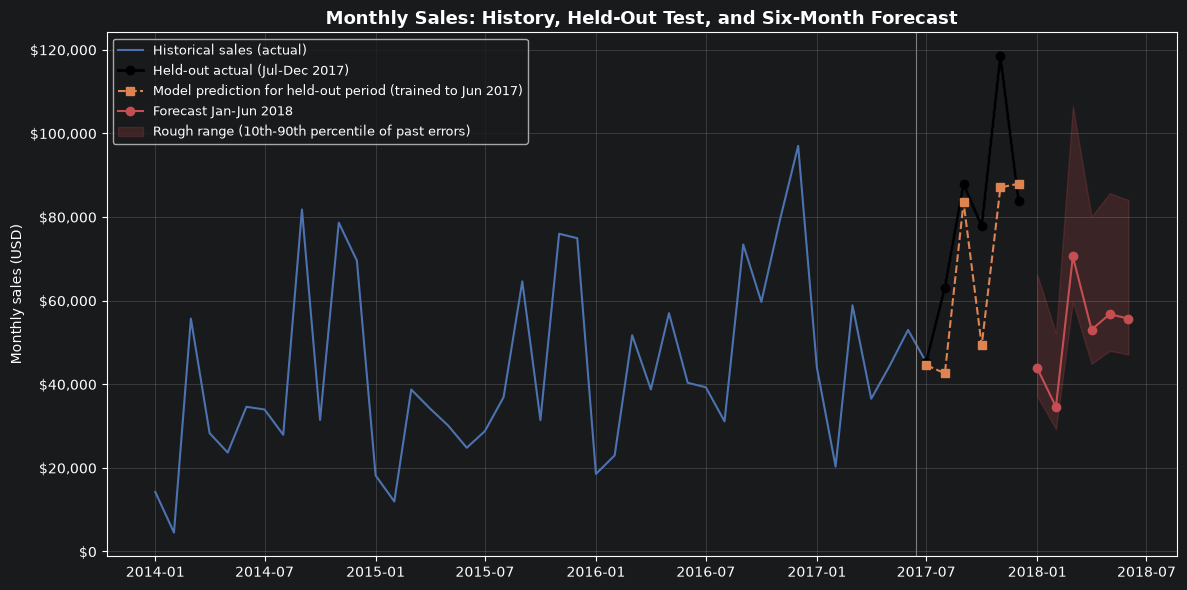

In [11]:
ratios = []
holdout_pred = None
for train_size in [30, 36, 42]:
    tr = sales.iloc[:train_size]
    te = sales.iloc[train_size:train_size + H]
    pred = holt_winters(tr)
    ratios.extend((te.values / pred).tolist())     # above 1 means the forecast was too low
    if train_size == 42:
        holdout_pred = pd.Series(pred, index=te.index)

low_ratio, median_ratio, high_ratio = np.quantile(ratios, [0.10, 0.50, 0.90])
print(f"Backtest forecasts: {len(ratios)} | ratio 10th {low_ratio:.2f}, median {median_ratio:.2f}, 90th {high_ratio:.2f}")

final = pd.Series(holt_winters(sales), index=pd.date_range("2018-01-01", periods=H, freq="MS"))
final_damped = pd.Series(holt_winters(sales, damped=True), index=final.index)
assert len(final) == 6 and (final > 0).all()

forecast_table = pd.DataFrame({
    "Forecast": final,
    "Low (10th pct)": final * low_ratio,
    "High (90th pct)": final * high_ratio,
    "Damped-trend comparison": final_damped,
})
forecast_table.index.name = "Month"

same_period_2017 = sales.loc["2017-01-01":"2017-06-01"].sum()
print(f"Forecast total Jan-Jun 2018:   ${final.sum():,.0f}")
print(f"Actual total Jan-Jun 2017:     ${same_period_2017:,.0f}")
print(f"Change vs same period of 2017: {final.sum() / same_period_2017 - 1:+.1%}")
print(f"Damped-trend model total:      ${final_damped.sum():,.0f}")
display(forecast_table.round(0))

out_file = project / "outputs" / "forecasts" / "sales_forecast_jan_jun_2018.csv"
out_file.parent.mkdir(parents=True, exist_ok=True)
forecast_table.round(2).to_csv(out_file)

held_out = sales.iloc[-H:]
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(sales.index, sales, color="#4C72B0", label="Historical sales (actual)")
ax.plot(held_out.index, held_out, color="black", marker="o", linewidth=2,
        label="Held-out actual (Jul-Dec 2017)")
ax.plot(holdout_pred.index, holdout_pred, color="#DD8452", linestyle="--", marker="s",
        label="Model prediction for held-out period (trained to Jun 2017)")
ax.plot(final.index, final, color="#C44E52", marker="o", label="Forecast Jan-Jun 2018")
ax.fill_between(final.index, forecast_table["Low (10th pct)"], forecast_table["High (90th pct)"],
                color="#C44E52", alpha=0.2, label="Rough range (10th-90th percentile of past errors)")
ax.axvline(pd.Timestamp("2017-06-15"), color="grey", linewidth=0.8)
ax.set_title("Monthly Sales: History, Held-Out Test, and Six-Month Forecast",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Monthly sales (USD)")
ax.yaxis.set_major_formatter(dollars)
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Findings: forecast

**What the data shows**
- The model forecasts about \$314K of sales for Jan to Jun 2018, 22.4% above the same months of 2017 (\$257K). March is the highest forecast month (\$70.5K) and February the lowest (\$34.6K).
- In testing, actual sales were more often above the forecast than below (10th percentile ratio 0.85, median 1.00, 90th percentile 1.51), so the range is wider on the upside.
- A second, damped-trend model forecasts \$360K for the same six months, about 15% higher.

**Interpretation** (my own reading)
- The two models disagree by about 15%, and the range is wide, so the forecast is best used as a planning range, not a single number.
- The upper side of the range is influenced by late 2017, when every model under-forecast.

**Limits**
- Only 48 months of data and 18 test forecasts, so the range is approximate.
- A few very large orders can move a month by 25% or more, and the model cannot predict them.
- Same-window selection and accuracy measurement means the reported error is a best-case figure.
- The data ends in Dec 2017, so this is a practice forecast, not a live prediction.

## 8. Conclusions and recommendations

### Summary of findings
- Sales grew from \$484K (2014) to \$733K (2017), and total profit was \$286K (a 12.5% margin). Orders grew faster than sales because the average order value fell.
- September, November and December each had an above-average share of sales in all four years. January and February were below average every year.
- Lines discounted above 20% lost about \$135K combined, equal to about 47% of total profit. Lines with no discount earned a 29.5% margin.
- Furniture had a 2.5% margin against about 17% for Technology and Office Supplies. Tables and Bookcases lost money overall.
- Central had the highest average discount (24.0%) and the lowest margin (7.9%).
- The Jan to Jun 2018 forecast is about \$314K (+22.4% against the same months of 2017), with a wide range, and a second model suggests about \$360K.

### Recommendations
1. **Review discounts above 20%.** These lines lose money overall. Check which products receive them and why before changing policy, because this analysis shows an association, not a cause.
2. **Review Furniture pricing, starting with Tables and Bookcases.** Sales are high but profit is small. Check costs, discounts and pricing for these items.
3. **Investigate Central region discounting.** Its margin is the lowest and its discounts the highest. Compare its product mix with other regions to see if discounts are the reason.
4. **Plan budgets and inventory around the forecast range, not a single figure.** Expect a slow January and February, then a stronger March, and stock up ahead of the September to December peak seen in every year.
5. **Track the forecast against actual sales monthly**, and refresh the model as new data arrives. Also track profit margin by discount band and the order count against average order value.

### Limits and future improvements
- Only 48 months of data and a small test set, so the accuracy and range are approximate.
- A few very large orders can move a month by 25% or more, and the model cannot predict them.
- The same test windows were used to choose the model and measure its accuracy, so the reported error is a best-case estimate.
- The currency is not stated in the file, and Superstore is a sample dataset, not a real company.
- The data ends in Dec 2017, so the forecast is a practice exercise, not a live prediction.
- Future work: more history, forecasts by category or region, other time-series models, and a closer look at which products receive heavy discounts and why.